# Prior Rollout Statistics

Net displacement, root height distributions, and 2D trajectory heatmaps
from H5 rollout datasets produced by `collect_rollout_dataset`.

In [9]:
import h5py
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
from pathlib import Path

matplotlib.rcParams["font.family"] = "DM Sans"

In [27]:
# ============ CONFIGURATION ============
# Two H5 files to compare
DATASET_PATH_A = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_rgm_54.h5"
DATASET_PATH_B = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_fc_49.h5"

LABEL_A = "Behavior Prior"
LABEL_B = "Motion Prior"

# Save path for figures
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots")
SAVE_NAME = "prior_rollout_stats"

In [28]:
def logvar_to_std(logvar: float) -> float:
    """Convert log-variance to standard deviation."""
    return np.exp(0.5 * logvar)


def parse_dataset_name(name: str, logvars: np.ndarray) -> dict:
    """Parse a qpos dataset name into noise level metadata.

    Handles both prior_* and rgm_* prefixed datasets.
    """
    stem = name.removesuffix("_qpos")

    if stem in ("prior_deterministic", "rgm_deterministic"):
        return {"std": 0.0, "sort_key": 0.0, "label": "deterministic"}
    elif stem in ("prior_predicted_logvar", "rgm_predicted_logvar"):
        return {"std": None, "sort_key": np.inf, "label": "predicted"}
    elif stem.startswith("prior_logvar_"):
        logvar_str = stem.removeprefix("prior_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    elif stem.startswith("rgm_logvar_"):
        logvar_str = stem.removeprefix("rgm_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    else:
        return {"std": None, "sort_key": np.inf, "label": stem}


def load_qpos_datasets(path):
    """Load all qpos datasets (except original) from an H5 file."""
    datasets = {}
    with h5py.File(path, "r") as f:
        logvars = f.attrs["logvars"]
        original_qpos = f["original_qpos"][:] if "original_qpos" in f else None
        for key in f.keys():
            if key.endswith("_qpos") and key != "original_qpos":
                datasets[key] = f[key][:]
    return datasets, logvars, original_qpos


qpos_a, logvars_a, original_qpos = load_qpos_datasets(DATASET_PATH_A)
qpos_b, logvars_b, _ = load_qpos_datasets(DATASET_PATH_B)
print(f"{LABEL_A}: {len(qpos_a)} datasets, logvars={logvars_a}")
print(f"{LABEL_B}: {len(qpos_b)} datasets, logvars={logvars_b}")
if original_qpos is not None:
    print(f"Original qpos: {original_qpos.shape}")

Behavior Prior: 9 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Motion Prior: 10 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Original qpos: (842, 250, 74)


## Net Displacement

Net displacement measures the straight-line distance from start to end of each rollout,
capturing how far the rodent actually walked rather than total path length.

In [29]:
def calculate_net_displacement(qpos: np.ndarray) -> np.ndarray:
    """Calculate straight-line distance from start to end for each rollout.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim) - first 2 elements are x, y.

    Returns:
        displacements: Shape (num_rollouts,) - net displacement per rollout.
    """
    return np.linalg.norm(qpos[:, -1, :2] - qpos[:, 0, :2], axis=1)


def build_displacement_df(qpos_datasets, logvars, method_label):
    """Build a DataFrame of per-clip net displacements for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        displacements = calculate_net_displacement(qpos)
        for clip_idx, disp in enumerate(displacements):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "displacement": disp,
                }
            )
    return pd.DataFrame(rows)


disp_df_a = build_displacement_df(qpos_a, logvars_a, LABEL_A)
disp_df_b = build_displacement_df(qpos_b, logvars_b, LABEL_B)
disp_df = pd.concat([disp_df_a, disp_df_b], ignore_index=True)

# Original (reference) baseline
original_disp = None
if original_qpos is not None:
    original_disp = calculate_net_displacement(original_qpos)
    print(f"Original (reference) net displacement: mean={original_disp.mean():.2f} +/- {original_disp.std():.2f}")

print(f"Total rollouts: {len(disp_df)} ({LABEL_A}: {len(disp_df_a)}, {LABEL_B}: {len(disp_df_b)})")

Original (reference) net displacement: mean=0.21 +/- 0.22
Total rollouts: 15998 (Behavior Prior: 7578, Motion Prior: 8420)


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_net_displacement_violin.[pdf|svg|png]


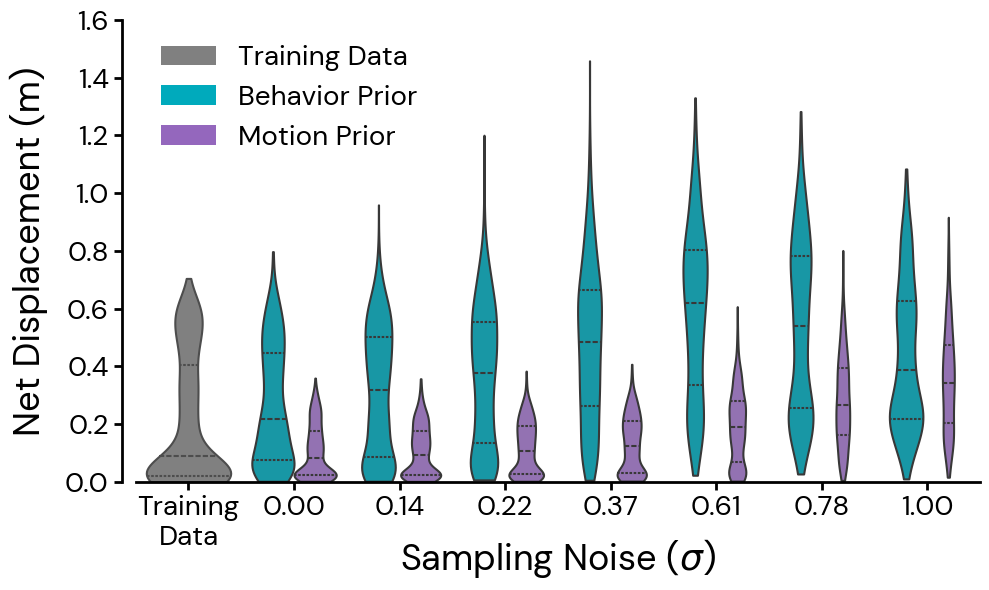

In [57]:
color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)
color_ref = (0.5, 0.5, 0.5)

# Build categorical sigma labels matching the KID plots
sigma_label_map = {
    "deterministic": "0.00",
    "std=0.135": "0.14",
    "std=0.223": "0.22",
    "std=0.368": "0.37",
    "std=0.607": "0.61",
    "std=0.779": "0.78",
    "std=1.000": "1.00",
}

violin_df = disp_df[disp_df["label"].isin(sigma_label_map)].copy()
violin_df["sigma"] = violin_df["label"].map(sigma_label_map)

sigma_order = ["Training\nData", "0.00", "0.14", "0.22", "0.37", "0.61", "0.78", "1.00"]

fig, ax = plt.subplots(figsize=(10, 6))

# 1) Reference: single centered violin (no hue splitting)
if original_disp is not None:
    ref_df = pd.DataFrame({
        "sigma": pd.Categorical(["Training\nData"] * len(original_disp),
                                categories=sigma_order, ordered=True),
        "displacement": original_disp,
    })
    sns.violinplot(
        data=ref_df, x="sigma", y="displacement",
        color=color_ref, inner="quart", linewidth=1.5,
        order=sigma_order, cut=0, ax=ax,
    )

# 2) Behavior Prior + Motion Prior: hue-split violins on remaining ticks
method_df = violin_df[violin_df["sigma"] != "Training\nData"].copy()
method_df["sigma"] = pd.Categorical(method_df["sigma"],
                                     categories=sigma_order, ordered=True)
palette = {LABEL_A: color_a, LABEL_B: color_b}

sns.violinplot(
    data=method_df, x="sigma", y="displacement", hue="method",
    inner="quart", palette=palette, linewidth=1.5,
    order=sigma_order, cut=0, ax=ax,
)

ax.set_ylim(0, 1.6)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=26, labelpad=-10)
ax.set_ylabel("Net Displacement (m)", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)

# Rebuild legend with all three entries
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=color_ref, label="Training Data"),
    Patch(facecolor=color_a, label=LABEL_A),
    Patch(facecolor=color_b, label=LABEL_B),
]
legend = ax.legend(handles=legend_handles, fontsize=20, frameon=False)
for handle in legend.legend_handles:
    handle.set_edgecolor("none")

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
if yticks:
    ax.spines["left"].set_bounds(yticks[0], yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
disp_violin_save = f"{SAVE_NAME}_net_displacement_violin"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{disp_violin_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / disp_violin_save}.[pdf|svg|png]")

plt.show()

## Proportion of Time Below Root Height

ECDF of root z-position across all rollouts, showing what fraction of time
the rodent spends below each height.

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_allnoise.[pdf|svg|png]


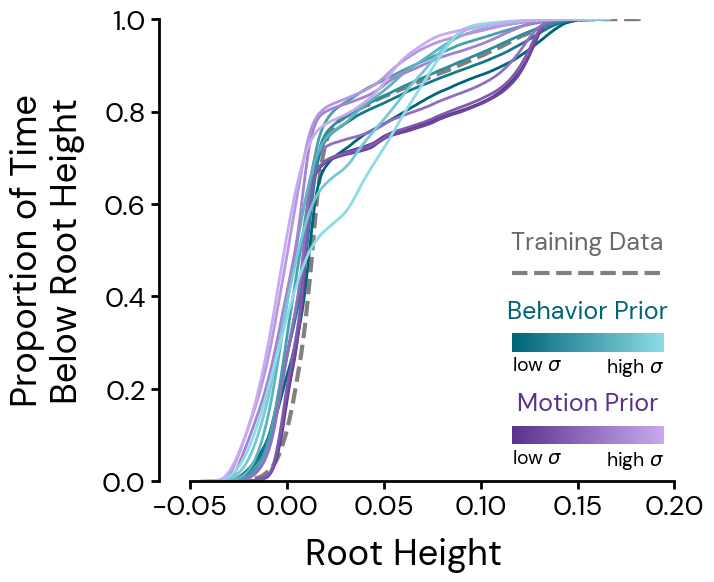

In [58]:
color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Training Data
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Training Data", ax=ax)

# Get sorted noise levels for alpha mapping
noise_levels = sorted(set(
    parse_dataset_name(name, logvars_a)["sort_key"]
    for name in qpos_a
    if np.isfinite(parse_dataset_name(name, logvars_a)["sort_key"])
))

# Sequential colormaps per method: dark → light within each hue family
color_a_dark = (0 / 255, 100 / 255, 120 / 255)   # dark teal
color_a_light = (140 / 255, 220 / 255, 230 / 255) # light cyan
color_b_dark = (90 / 255, 50 / 255, 140 / 255)    # dark purple
color_b_light = (200 / 255, 170 / 255, 240 / 255) # light lavender

cmap_a = LinearSegmentedColormap.from_list('scamper', [color_a_dark, color_a_light])
cmap_b = LinearSegmentedColormap.from_list('pulse', [color_b_dark, color_b_light])

n_levels = len(noise_levels)
fracs = [i / max(n_levels - 1, 1) for i in range(n_levels)]

# Draw individual curves per noise level
for noise, frac in zip(noise_levels, fracs):
    # Behavior Prior
    for name, qpos in qpos_a.items():
        info = parse_dataset_name(name, logvars_a)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_a(frac), linewidth=2, ax=ax,
                         label="_nolegend_")
    # Motion Prior
    for name, qpos in qpos_b.items():
        info = parse_dataset_name(name, logvars_b)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_b(frac), linewidth=2, ax=ax,
                         label="_nolegend_")

ax.set_xlabel("Root Height", fontsize=26, labelpad=12)
ax.set_ylabel("Proportion of Time\nBelow Root Height", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)


# Legend: colorbars + labels using ax.text() for stable PDF rendering
cbar_w = 0.28
cbar_h = 0.04
cbar_x = 1.0 - cbar_w - 0.02
base_y = 0.08
y_positions = [base_y, base_y + 0.20]  # Motion Prior, Behavior Prior
ref_offset = 0.15  # smaller gap Training Data-Behavior Prior

legend_items = [
    (cmap_b, LABEL_B, color_b_dark),
    (cmap_a, LABEL_A, color_a_dark),
]

for i, (cmap, label, title_color) in enumerate(legend_items):
    y = y_positions[i]
    # Gradient bar
    cbar_ax = ax.inset_axes([cbar_x, y, cbar_w, cbar_h])
    gradient = np.linspace(0, 1, 256).reshape(1, -1)
    cbar_ax.imshow(gradient, aspect="auto", cmap=cmap)
    cbar_ax.set_axis_off()
    # Labels using ax.text (axes coords)
    ax.text(cbar_x + cbar_w / 2, y + cbar_h + 0.02, label,
            transform=ax.transAxes, fontsize=18, color=title_color,
            ha="center", va="bottom")
    ax.text(cbar_x, y - 0.01, r"low $\sigma$",
            transform=ax.transAxes, fontsize=14, ha="left", va="top")
    ax.text(cbar_x + cbar_w, y - 0.01, r"high $\sigma$",
            transform=ax.transAxes, fontsize=14, ha="right", va="top")

# Training Data entry
ref_y = y_positions[1] + ref_offset
ref_ax = ax.inset_axes([cbar_x, ref_y, cbar_w, cbar_h])
ref_ax.plot([0, 1], [0.5, 0.5], color="gray", linestyle="--", linewidth=3,
            transform=ref_ax.transAxes, clip_on=False)
ref_ax.set_axis_off()
ax.text(cbar_x + cbar_w / 2, ref_y + cbar_h + 0.02, "Training Data",
        transform=ax.transAxes, fontsize=18, color="dimgray",
        ha="center", va="bottom")

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["left"].set_position(("axes", 0.05))
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)


# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf_allnoise"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_predicted.[pdf|svg|png]


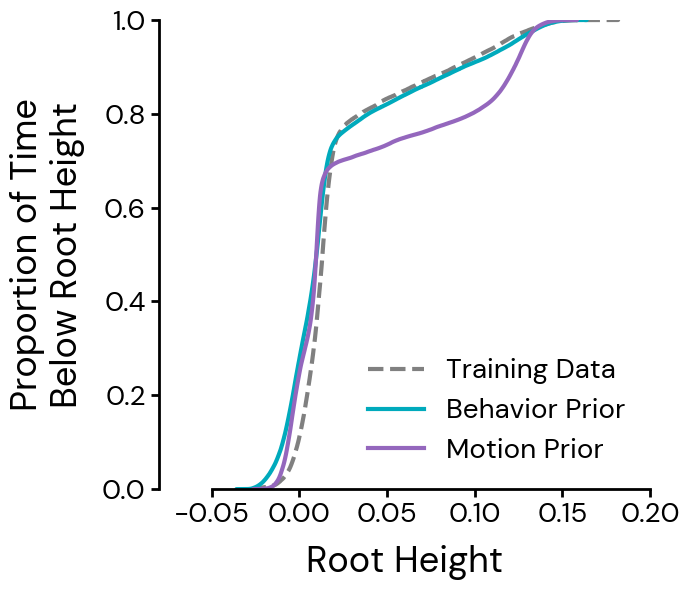

In [59]:
color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Training Data
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Training Data", ax=ax)

# Predicted logvar curves
for method_label, qpos_datasets, logvars, color in [
    (LABEL_A, qpos_a, logvars_a, color_a),
    (LABEL_B, qpos_b, logvars_b, color_b),
]:
    for name, qpos in qpos_datasets.items():
        info = parse_dataset_name(name, logvars)
        if info["label"] == "predicted":
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=color, linewidth=3, label=method_label, ax=ax)

ax.set_xlabel("Root Height", fontsize=26, labelpad=12)
ax.set_ylabel("Proportion of Time\nBelow Root Height", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)
ax.legend(fontsize=20, frameon=False)

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf_predicted"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()

[deterministic] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_deterministic.[pdf|svg|png]


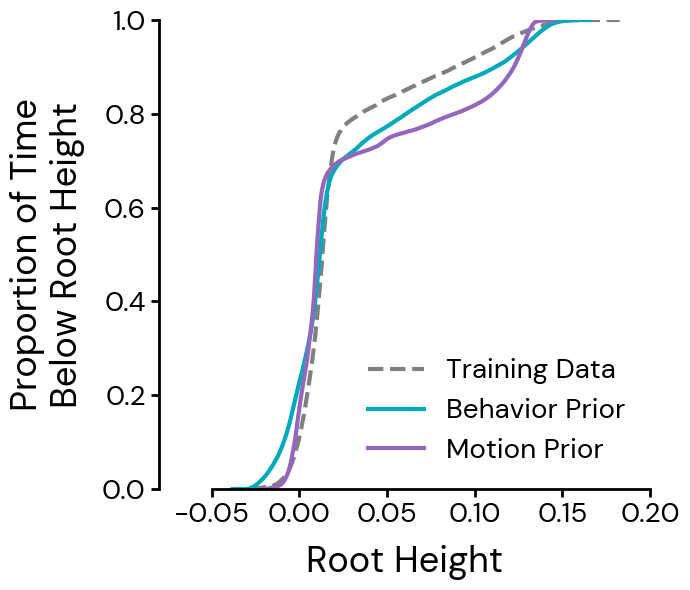

[std=0.135] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std0.135.[pdf|svg|png]


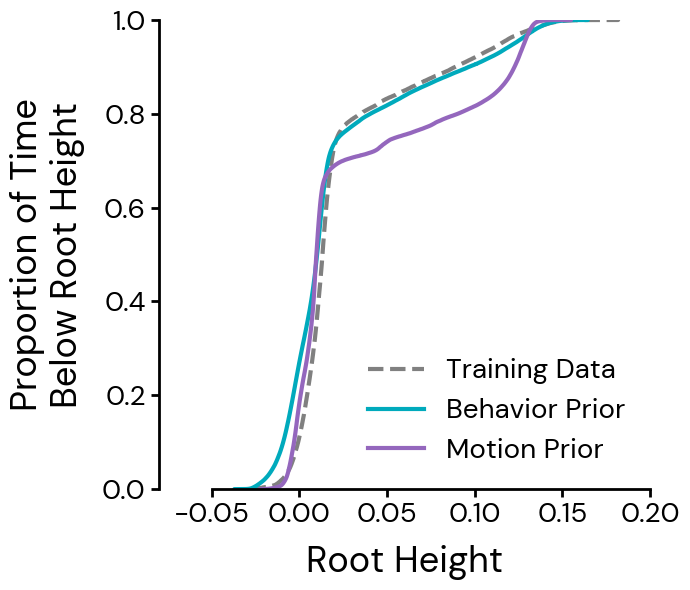

[std=0.223] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std0.223.[pdf|svg|png]


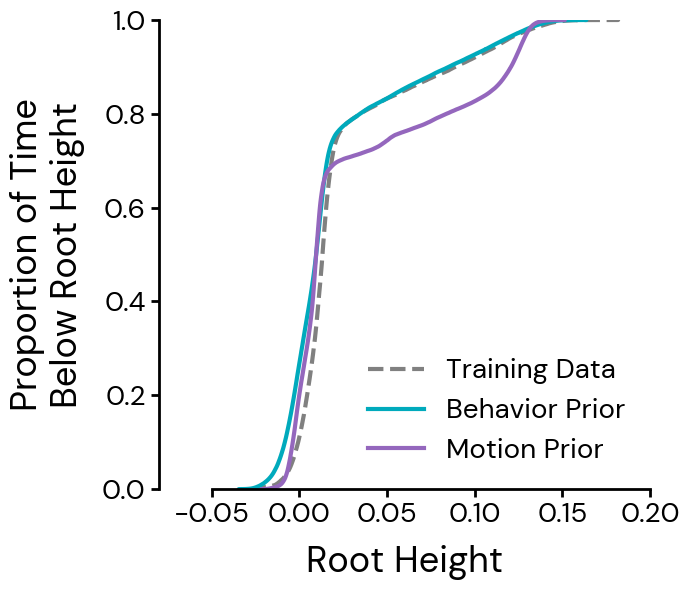

[std=0.368] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std0.368.[pdf|svg|png]


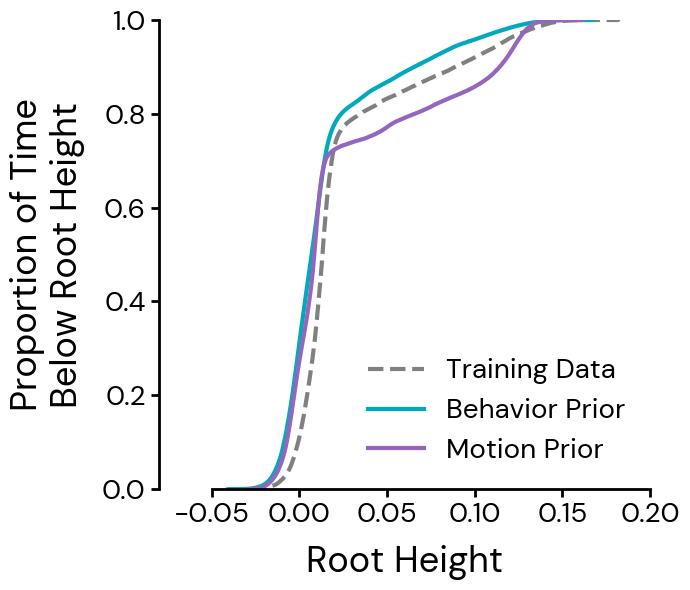

[std=0.607] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std0.607.[pdf|svg|png]


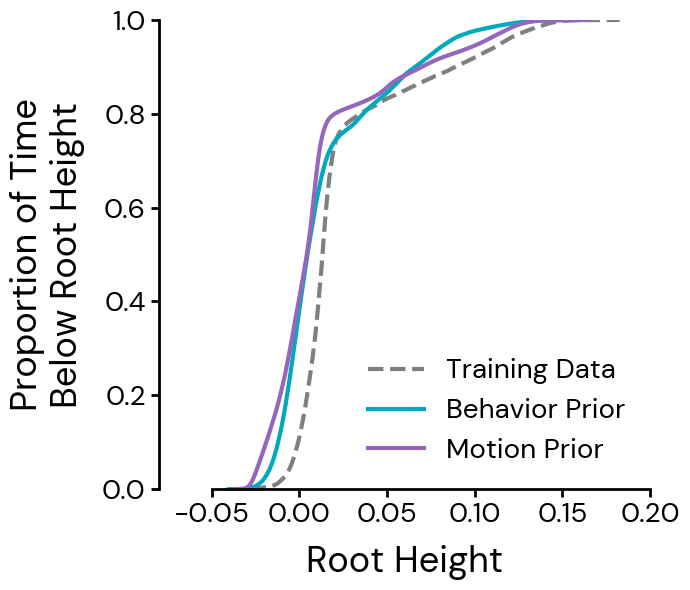

[std=0.779] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std0.779.[pdf|svg|png]


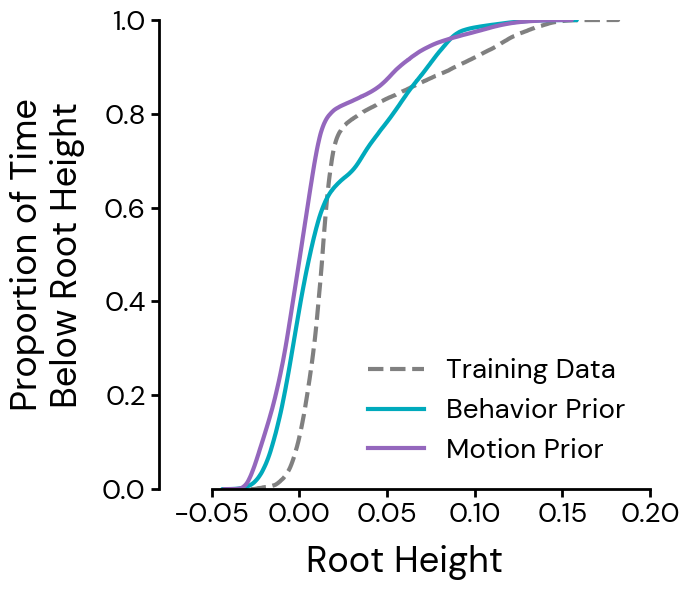

[std=1.000] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_z_height_ecdf_std1.000.[pdf|svg|png]


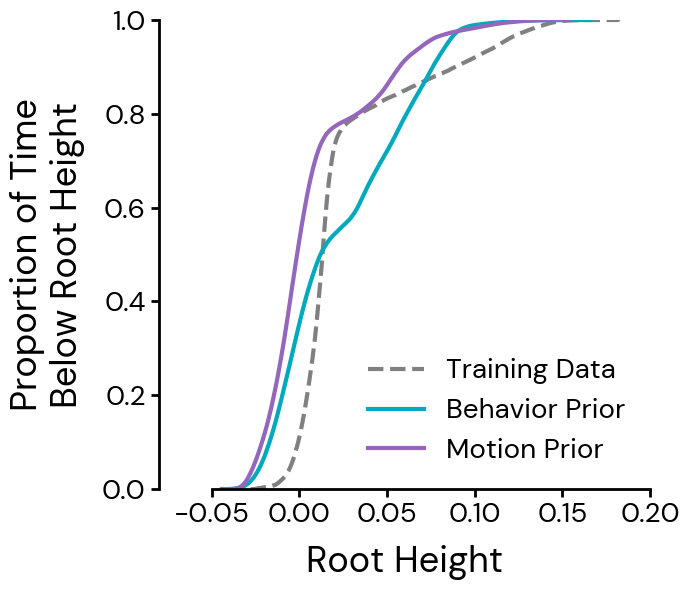

In [60]:
color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Collect all unique noise labels across both methods.
# Only keep finite sort_key (excludes predicted logvar and unrecognized datasets
# like student_encoder_decoder which all get sort_key=inf).
all_noise_labels = {}
for name in list(qpos_a.keys()) + list(qpos_b.keys()):
    logvars = logvars_a if name in qpos_a else logvars_b
    info = parse_dataset_name(name, logvars)
    label = info["label"]
    if np.isfinite(info["sort_key"]):
        all_noise_labels[label] = info["sort_key"]

# Sort by noise level (deterministic=0 first, then ascending std)
sorted_noise = sorted(all_noise_labels.items(), key=lambda x: x[1])

for noise_label, sort_key in sorted_noise:
    fig, ax = plt.subplots(figsize=(7, 6))

    # Training Data
    if original_qpos is not None:
        z_ref = original_qpos[:, :, 2].ravel()
        z_ref = z_ref[z_ref >= -0.05]
        sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Training Data", ax=ax)

    # Behavior Prior
    for name, qpos in qpos_a.items():
        info = parse_dataset_name(name, logvars_a)
        if info["label"] == noise_label:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=color_a, linewidth=3, label=LABEL_A, ax=ax)

    # Motion Prior
    for name, qpos in qpos_b.items():
        info = parse_dataset_name(name, logvars_b)
        if info["label"] == noise_label:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=color_b, linewidth=3, label=LABEL_B, ax=ax)

    # Title from noise label
    if noise_label == "deterministic":
        title_str = r"Deterministic ($\sigma$ = 0)"
    else:
        std_val = sort_key
        title_str = rf"$\sigma$ = {std_val:.3f}"

    ax.set_xlabel("Root Height", fontsize=26, labelpad=12)
    ax.set_ylabel("Proportion of Time\nBelow Root Height", fontsize=26, labelpad=12)
    ax.tick_params(labelsize=20, width=2, length=6)
    ax.legend(fontsize=20, frameon=False)

    ax.set_xlim(-0.08, 0.20)
    ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

    sns.despine(ax=ax)
    ax.spines["bottom"].set_bounds(-0.05, 0.20)
    ax.spines["left"].set_bounds(0.0, 1.0)

    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(2)

    plt.tight_layout()

    # Save
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    safe_label = noise_label.replace("=", "").replace(" ", "_")
    z_save = f"{SAVE_NAME}_z_height_ecdf_{safe_label}"
    for ext in ["pdf", "svg", "png"]:
        fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
    print(f"[{noise_label}] Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

    plt.show()

## Wasserstein Distance to Training Data

Earth mover's distance between each method's root-height distribution and
the reference, at every noise level. Lower = closer to reference.

Wasserstein distance (root height) vs Training Data
method     Behavior Prior  Motion Prior
sigma                                  
0.00               0.0085        0.0116
0.14               0.0054        0.0121
0.22               0.0045        0.0115
0.37               0.0092        0.0099
0.61               0.0106        0.0126
0.78               0.0129        0.0171
1.00               0.0162        0.0173
Predicted          0.0053        0.0137

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_wasserstein_root_height.[pdf|svg|png]


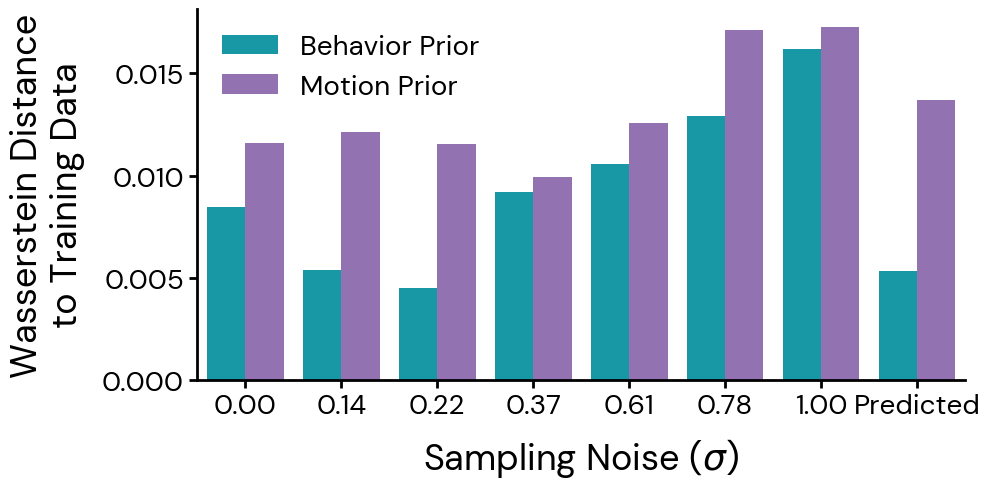

In [61]:
from scipy.stats import wasserstein_distance

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Training Data root-height distribution (filtered same as ECDF plots)
z_ref = original_qpos[:, :, 2].ravel()
z_ref = z_ref[z_ref >= -0.05]

# Collect all noise labels (finite sort_key + predicted)
all_noise_labels = {}
for name in list(qpos_a.keys()) + list(qpos_b.keys()):
    logvars = logvars_a if name in qpos_a else logvars_b
    info = parse_dataset_name(name, logvars)
    label = info["label"]
    if np.isfinite(info["sort_key"]) or label == "predicted":
        all_noise_labels[label] = info["sort_key"]

sorted_noise = sorted(all_noise_labels.items(), key=lambda x: (x[1], x[0]))

# Compute Wasserstein distance for each (method, noise_level) vs reference
rows = []
for noise_label, sort_key in sorted_noise:
    # Behavior Prior
    for name, qpos in qpos_a.items():
        info = parse_dataset_name(name, logvars_a)
        if info["label"] == noise_label:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            wd = wasserstein_distance(z_ref, z)
            rows.append({"method": LABEL_A, "noise_label": noise_label,
                         "sort_key": sort_key, "wasserstein": wd})
    # Motion Prior
    for name, qpos in qpos_b.items():
        info = parse_dataset_name(name, logvars_b)
        if info["label"] == noise_label:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            wd = wasserstein_distance(z_ref, z)
            rows.append({"method": LABEL_B, "noise_label": noise_label,
                         "sort_key": sort_key, "wasserstein": wd})

wd_df = pd.DataFrame(rows)

# Build display labels matching the sigma_label_map used elsewhere
sigma_display = {
    "deterministic": "0.00",
    "std=0.135": "0.14",
    "std=0.223": "0.22",
    "std=0.368": "0.37",
    "std=0.607": "0.61",
    "std=0.779": "0.78",
    "std=1.000": "1.00",
    "predicted": "Predicted",
}
wd_df["sigma"] = wd_df["noise_label"].map(sigma_display).fillna(wd_df["noise_label"])

# Print table
print("Wasserstein distance (root height) vs Training Data")
print("=" * 55)
pivot = wd_df.pivot(index="sigma", columns="method", values="wasserstein")
# Reorder rows by sort_key
order = wd_df.drop_duplicates("sigma").sort_values("sort_key")["sigma"].tolist()
pivot = pivot.reindex(order)
print(pivot.to_string(float_format=lambda x: f"{x:.4f}"))

# Bar chart
sigma_order = [s for s in order if s in wd_df["sigma"].values]
wd_df["sigma"] = pd.Categorical(wd_df["sigma"], categories=sigma_order, ordered=True)

fig, ax = plt.subplots(figsize=(10, 5))
palette = {LABEL_A: color_a, LABEL_B: color_b}

sns.barplot(
    data=wd_df, x="sigma", y="wasserstein", hue="method",
    palette=palette, order=sigma_order, ax=ax,
)

ax.set_xlabel(r"Sampling Noise ($\sigma$)", fontsize=26, labelpad=12)
ax.set_ylabel("Wasserstein Distance\nto Training Data", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)
ax.legend(fontsize=20, frameon=False)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
wd_save = f"{SAVE_NAME}_wasserstein_root_height"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{wd_save}.{ext}", bbox_inches="tight")
print(f"\nSaved to {SAVE_DIR / wd_save}.[pdf|svg|png]")

plt.show()

## 2D Trajectory Heatmaps

Density heatmaps of all rollout XY trajectories, comparing reference, Behavior Prior, and Motion Prior.
Uses the predicted log-variance rollouts (the most natural sampling mode).
Immediately shows whether the rodent is exploring space vs standing still.

[deterministic] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_deterministic.[pdf|svg|png]


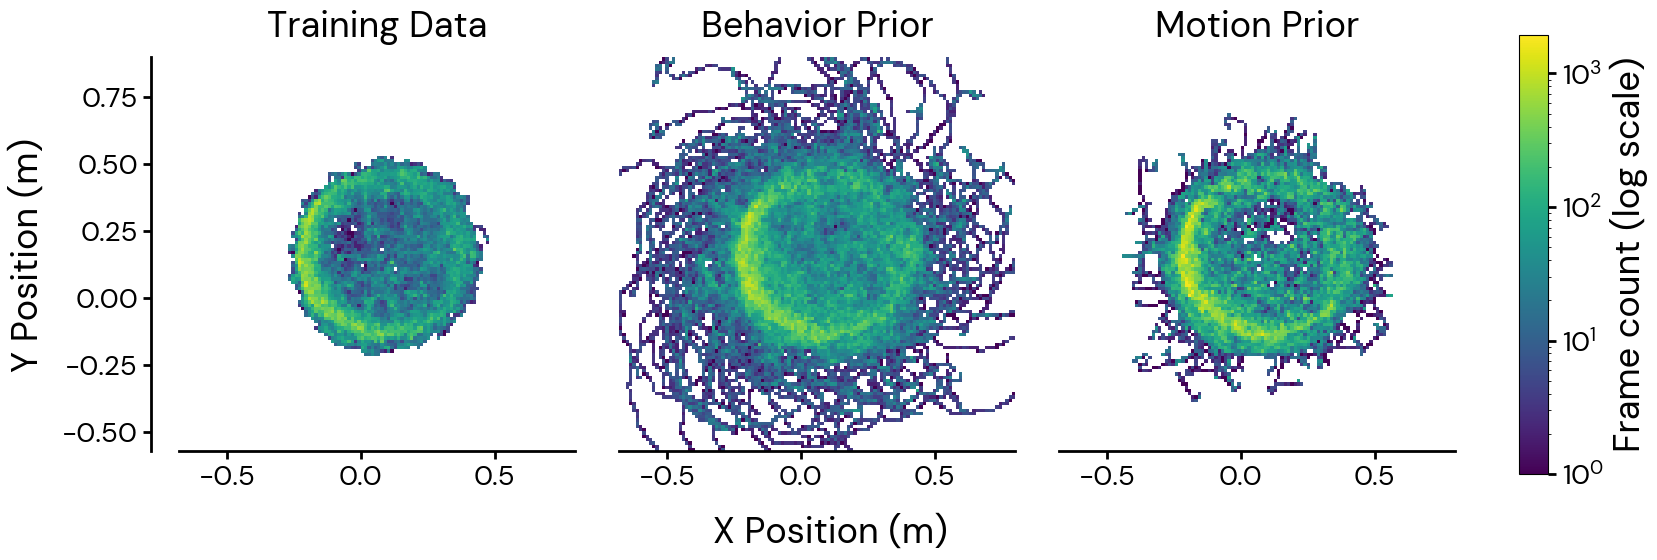

[std=0.135] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std0.135.[pdf|svg|png]


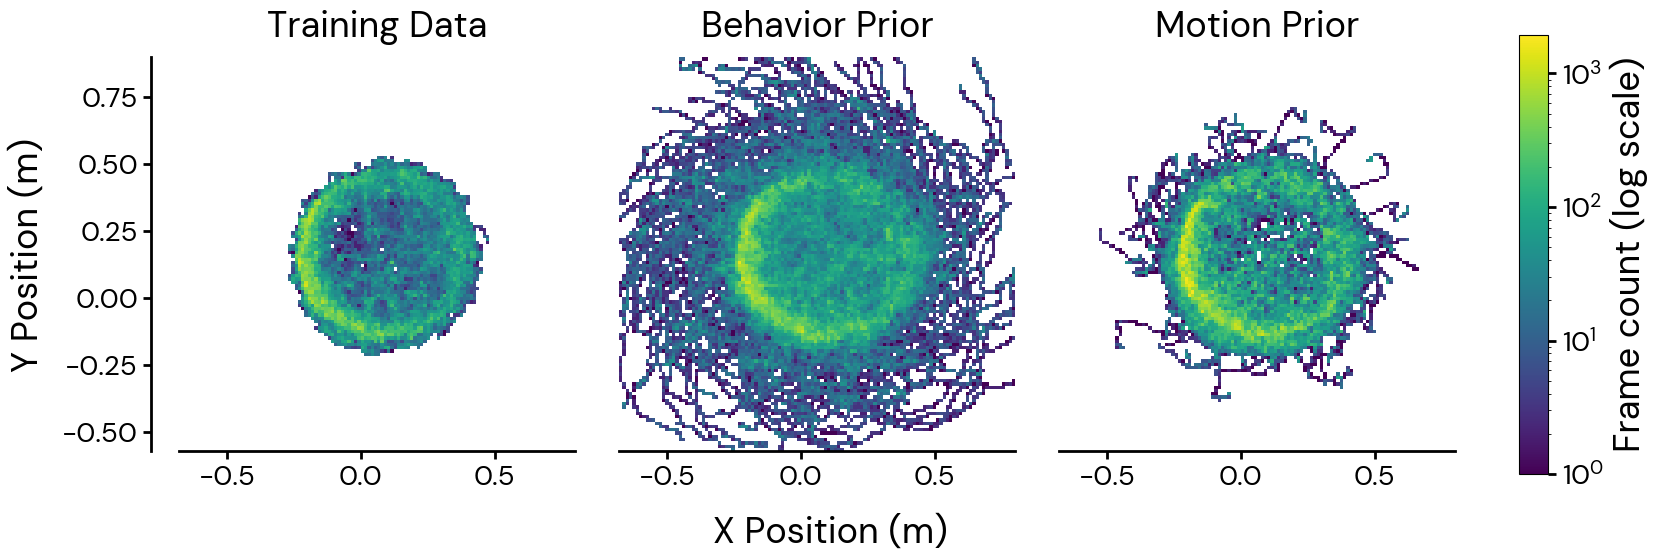

[std=0.223] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std0.223.[pdf|svg|png]


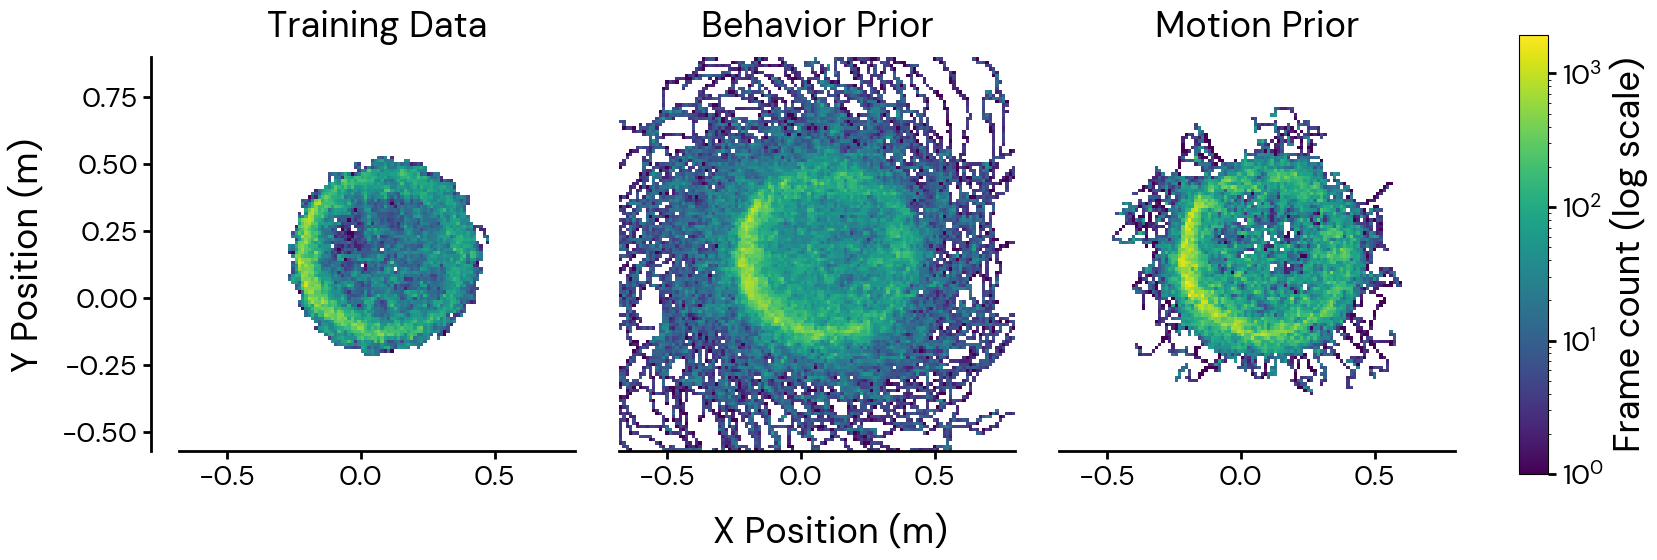

[std=0.368] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std0.368.[pdf|svg|png]


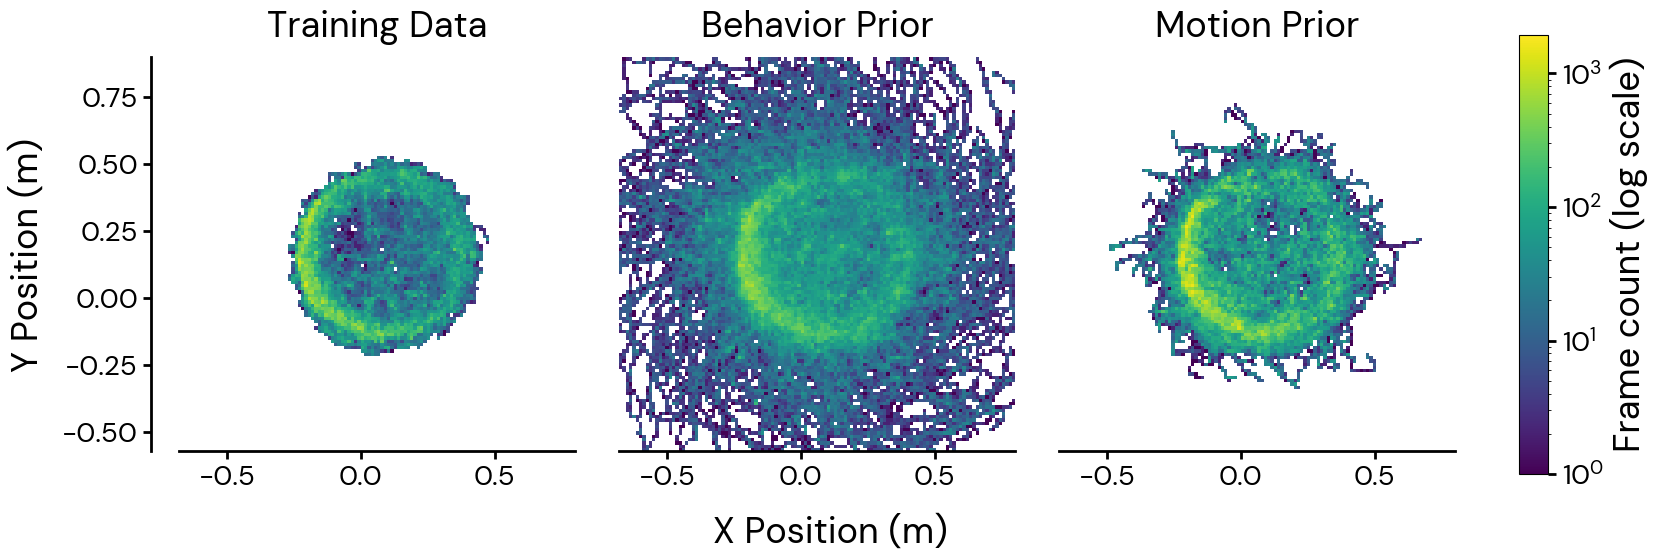

[std=0.607] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std0.607.[pdf|svg|png]


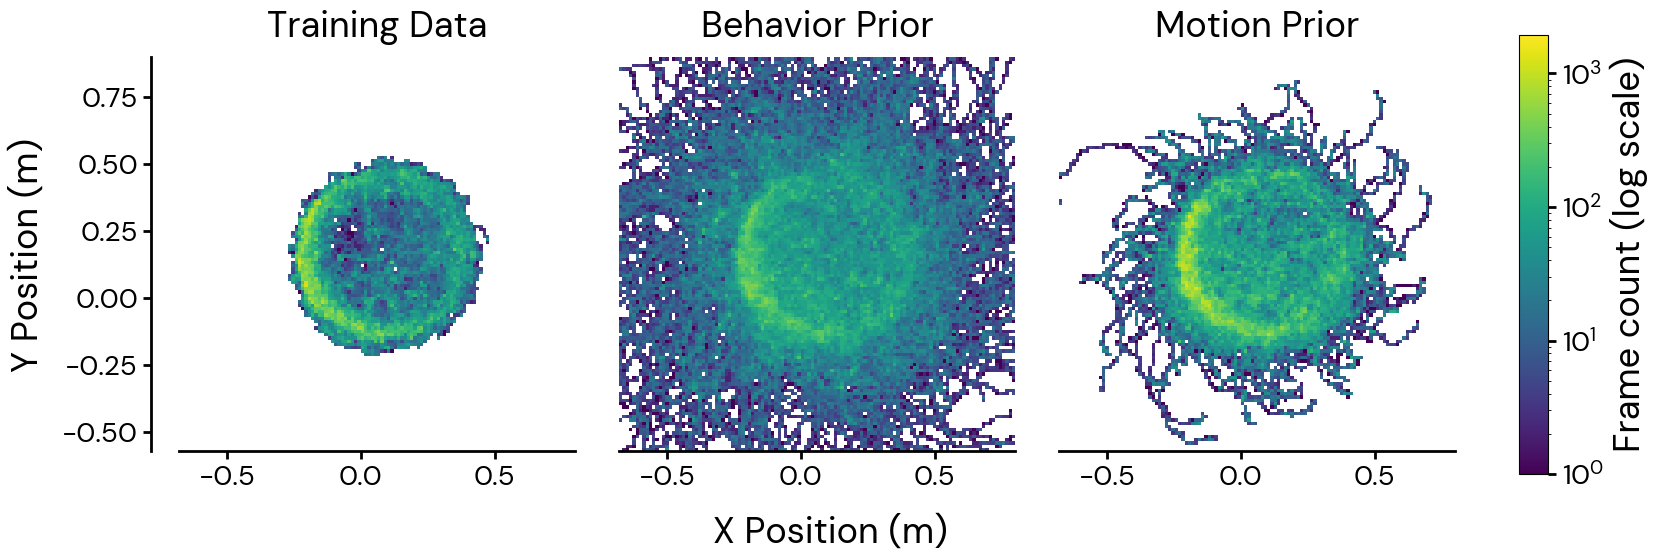

[std=0.779] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std0.779.[pdf|svg|png]


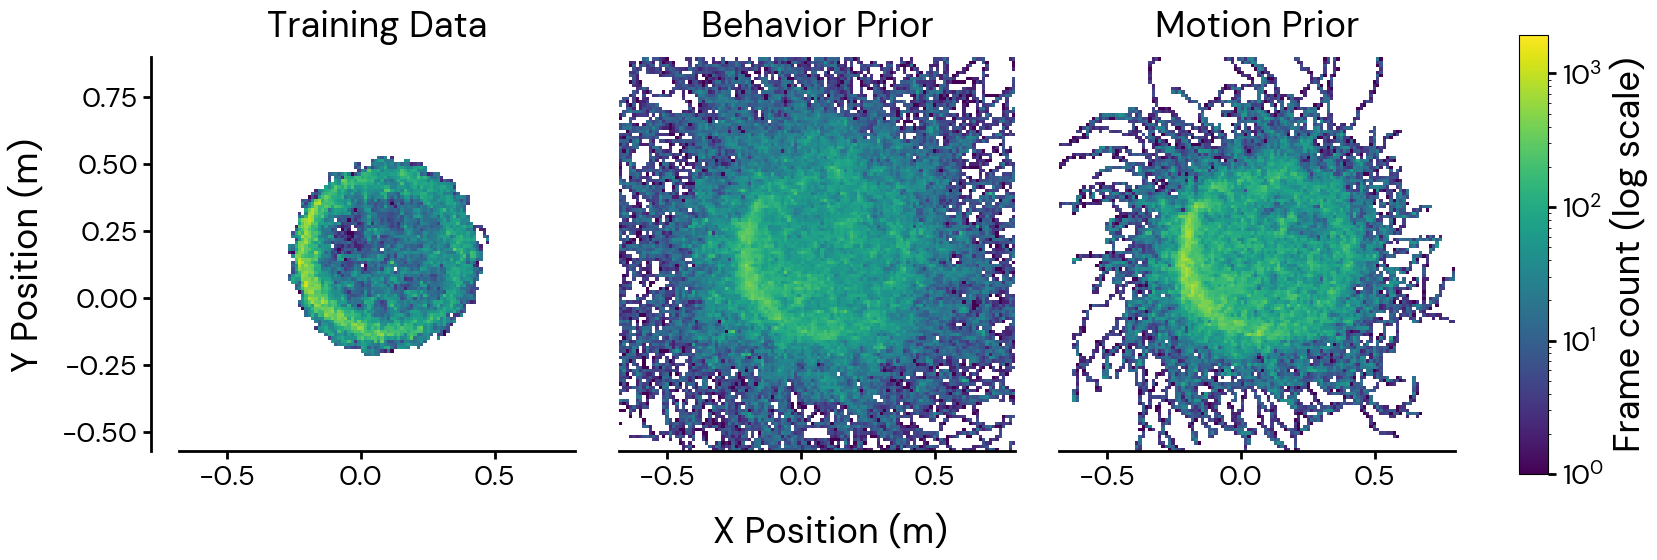

[std=1.000] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_std1.000.[pdf|svg|png]


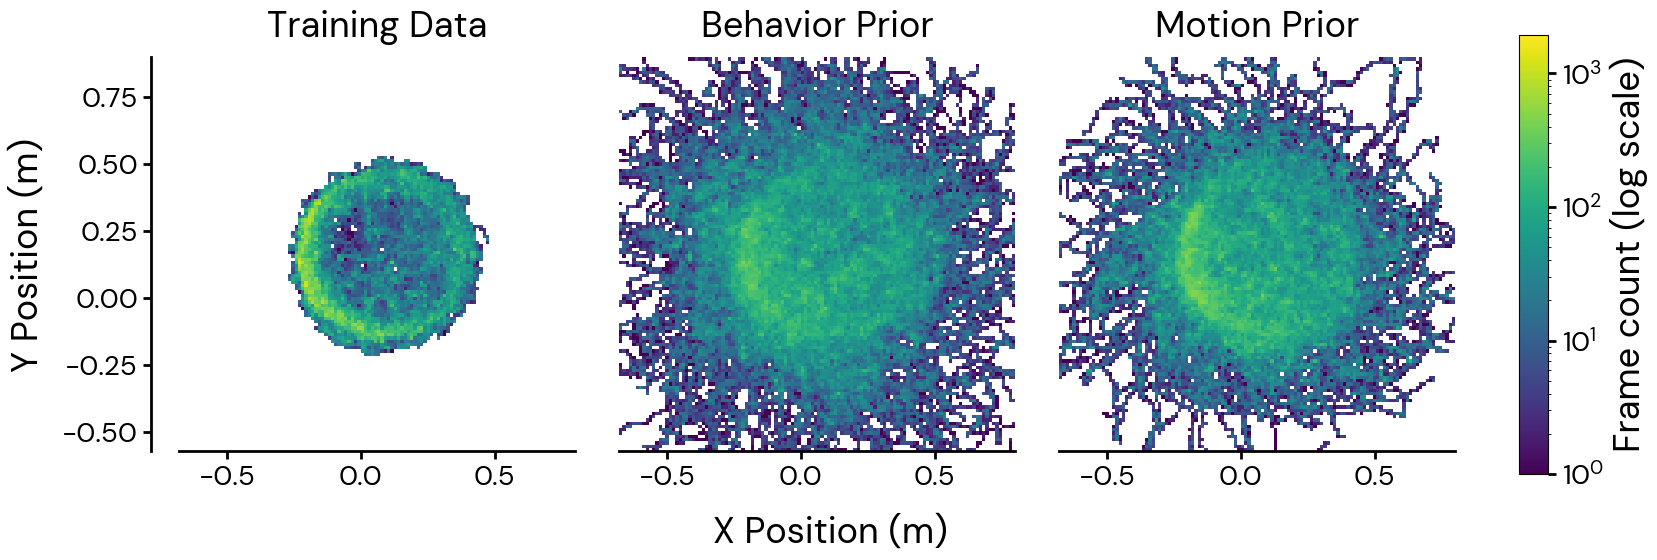

[predicted] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/prior_rollout_stats_trajectory_heatmap_predicted.[pdf|svg|png]


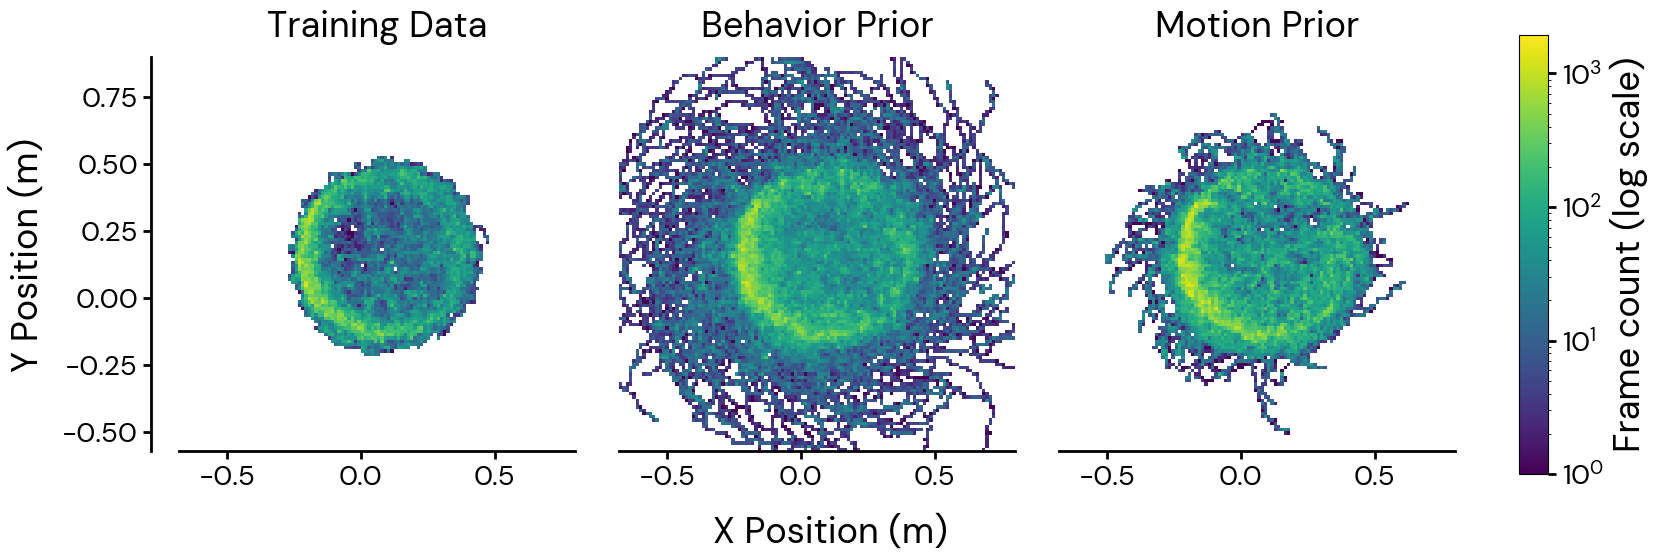

In [62]:
# Build list of (noise_label, sort_key, qpos_a, qpos_b)
# Match datasets across methods by parsed label
datasets_by_label = {}
for ds_name, qpos in qpos_a.items():
    if not (ds_name.startswith("prior_") or ds_name.startswith("rgm_")):
        continue
    info = parse_dataset_name(ds_name, logvars_a)
    key = info["label"]
    datasets_by_label.setdefault(key, {"sort_key": info["sort_key"], "label": key})
    datasets_by_label[key]["qpos_a"] = qpos
for ds_name, qpos in qpos_b.items():
    if not (ds_name.startswith("prior_") or ds_name.startswith("rgm_")):
        continue
    info = parse_dataset_name(ds_name, logvars_b)
    key = info["label"]
    datasets_by_label.setdefault(key, {"sort_key": info["sort_key"], "label": key})
    datasets_by_label[key]["qpos_b"] = qpos

# Sort by noise level
sorted_labels = sorted(datasets_by_label.values(), key=lambda d: d["sort_key"])

# Compute shared axis limits across ALL datasets + reference
all_x, all_y = [], []
if original_qpos is not None:
    all_x.append(original_qpos[:, :, 0].ravel())
    all_y.append(original_qpos[:, :, 1].ravel())
for d in sorted_labels:
    for k in ["qpos_a", "qpos_b"]:
        if k in d:
            all_x.append(d[k][:, :, 0].ravel())
            all_y.append(d[k][:, :, 1].ravel())
all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)
pad = 0.15
x_range = (np.percentile(all_x, 1) - pad, np.percentile(all_x, 99) + pad)
y_range = (np.percentile(all_y, 1) - pad, np.percentile(all_y, 99) + pad)

bins = 120

# Precompute all histograms to find shared vmax
def make_hist(qpos):
    x = qpos[:, :, 0].ravel()
    y = qpos[:, :, 1].ravel()
    h, _, _ = np.histogram2d(x, y, bins=bins, range=[x_range, y_range])
    return h

all_hists = []
if original_qpos is not None:
    all_hists.append(make_hist(original_qpos))
for d in sorted_labels:
    for k in ["qpos_a", "qpos_b"]:
        if k in d:
            all_hists.append(make_hist(d[k]))
shared_vmax = max(h.max() for h in all_hists)

# One figure per noise level: Training Data | Behavior Prior | Motion Prior
for entry in sorted_labels:
    label = entry["label"]
    panels = []
    if original_qpos is not None:
        panels.append(("Training Data", original_qpos))
    if "qpos_a" in entry:
        panels.append((LABEL_A, entry["qpos_a"]))
    if "qpos_b" in entry:
        panels.append((LABEL_B, entry["qpos_b"]))

    ncols = len(panels)
    fig, axes = plt.subplots(
        1, ncols, figsize=(5 * ncols + 1.5, 5),
        constrained_layout=True,
    )
    fig.get_layout_engine().set(wspace=0.08)
    if ncols == 1:
        axes = [axes]

    for ax, (title, qpos) in zip(axes, panels):
        h = make_hist(qpos)
        h_plot = np.ma.masked_where(h.T == 0, h.T)
        im = ax.pcolormesh(
            np.linspace(*x_range, bins + 1),
            np.linspace(*y_range, bins + 1),
            h_plot,
            norm=mcolors.LogNorm(vmin=1, vmax=shared_vmax),
            cmap="viridis",
            rasterized=True,
        )
        ax.set_title(title, fontsize=26, pad=15)
        ax.set_aspect("equal")
        ax.tick_params(labelsize=20, width=2, length=6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["bottom"].set_linewidth(2)
        ax.spines["left"].set_linewidth(2)

    # Offset left spine on first panel to create gap between x and y spines
    axes[0].spines["left"].set_position(("outward", 20))
    axes[0].set_ylabel("Y Position (m)", fontsize=26, labelpad=12)
    for ax in axes[1:]:
        ax.set_yticklabels([])
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)

    # Single shared x label centered under all panels
    fig.supxlabel("X Position (m)", fontsize=26, y=-0.1)

    cbar = fig.colorbar(im, ax=axes, label="Frame Count (log scale)", shrink=1.0, aspect=15)
    cbar.ax.tick_params(labelsize=20, width=2, length=6)
    cbar.set_label("Frame count (log scale)", fontsize=26)

    # Save
    safe_label = label.replace("=", "").replace(" ", "_")
    save_base = SAVE_DIR / f"{SAVE_NAME}_trajectory_heatmap_{safe_label}"
    for ext in ["pdf", "svg", "png"]:
        fig.savefig(f"{save_base}.{ext}", dpi=300, bbox_inches="tight")
    print(f"[{label}] Saved to {save_base}.[pdf|svg|png]")

    plt.show()